# U-Net Denoising Autoencoder cho Dataset NoisyOffice

> **Mục tiêu:** Huấn luyện mô hình U-Net để khử nhiễu ảnh văn bản bẩn, phục hồi lại ảnh sạch (binary).  
> **Dataset:** [NoisyOffice](https://archive.ics.uci.edu/dataset/318/noisyoffice) — chứa 216 ảnh văn bản mô phỏng nhiễu (cà phê, nếp gấp, giấy cũ, nếp nhăn) và 54 ảnh sạch tương ứng.  
> **Đánh giá:** RMSE giữa ảnh dự đoán và ảnh sạch (Ground Truth).  
---

## 1. Môi trường và Thư viện

In [8]:
import os
import re
import glob
import random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as T
import torchvision.transforms.functional as TF

# ---- Thiết lập Random Seed (Reproducibility) ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Tải và Giải nén Dataset NoisyOffice

Bạn cần upload file `NoisyOffice.zip` lên Colab hoặc mount Google Drive. Cell dưới đây xử lý cả hai trường hợp.

In [12]:
# Duong dan toi dataset NoisyOffice tren Google Drive
DATASET_ROOT = '/content/drive/MyDrive/DAT301_SE190840_NguyenPhuongVu_Assigments/OCR_Testing/NoisyOffice'

# Kiem tra dataset
for name, sub in [('Simulated Noisy', 'SimulatedNoisyOffice/simulated_noisy_images_grayscale'),
                   ('Clean Binary', 'SimulatedNoisyOffice/clean_images_binaryscale'),
                   ('Real Noisy', 'RealNoisyOffice/real_noisy_images_grayscale')]:
    path = os.path.join(DATASET_ROOT, sub)
    if os.path.exists(path):
        n = len(glob.glob(os.path.join(path, '*.png')))
        print(f'[OK] {name}: {n} images found')
    else:
        print(f'[FAIL] {name}: NOT FOUND -- check DATASET_ROOT!')


[OK] Simulated Noisy: 216 images found
[OK] Clean Binary: 54 images found
[OK] Real Noisy: 72 images found


## 3. Cấu hình Tham số (CFG)

In [13]:
class CFG:
    # ---- Duong dan (Paths) ----
    NOISY_DIR       = os.path.join(DATASET_ROOT, 'SimulatedNoisyOffice', 'simulated_noisy_images_grayscale')
    CLEAN_DIR       = os.path.join(DATASET_ROOT, 'SimulatedNoisyOffice', 'clean_images_binaryscale')
    REAL_NOISY_DIR  = os.path.join(DATASET_ROOT, 'RealNoisyOffice', 'real_noisy_images_grayscale')

    # ---- Sieu tham so huan luyen ----
    IMG_SIZE       = 256       # Resize toan bo anh ve 256x256
    BATCH_SIZE     = 8
    NUM_WORKERS    = 2
    EPOCHS         = 80
    LR             = 1e-3
    WEIGHT_DECAY   = 1e-5
    VAL_RATIO      = 0.15      # Ti le tap Validation

    # ---- Cau truc UNet ----
    BASE_CH        = 64        # So kenh (channels) lop dau tien


## 4. Xây dựng cặp dữ liệu (Noisy → Clean)

> **Lưu ý quan trọng:** Trong NoisyOffice, tên file noisy và clean **KHÔNG giống nhau**:  
> - Noisy: `FontLre_Noisec_TE.png` (có chứa loại nhiễu: `c`=coffee, `f`=folded, `p`=print, `w`=wrinkled)  
> - Clean: `FontLre_Clean_TE.png`  
>
> Ta cần viết hàm ghép cặp: thay `Noise{x}` bằng `Clean` trong tên file.

In [14]:
def build_noisy_clean_pairs(noisy_dir, clean_dir):
    """
    Ghép cặp (noisy_path, clean_path) cho NoisyOffice.
    Tên file noisy: FontXXX_NoiseY_ZZ.png  →  Clean: FontXXX_Clean_ZZ.png
    """
    noisy_paths = sorted(glob.glob(os.path.join(noisy_dir, '*.png')))
    pairs = []

    for noisy_path in noisy_paths:
        fname = os.path.basename(noisy_path)
        # Thay thế phần 'Noise{x}' bằng 'Clean'
        clean_fname = re.sub(r'Noise[a-z]', 'Clean', fname)
        clean_path = os.path.join(clean_dir, clean_fname)

        if os.path.exists(clean_path):
            pairs.append((noisy_path, clean_path))
        else:
            print(f"[CẢNH BÁO] Không tìm thấy ảnh sạch cho: {fname} → {clean_fname}")

    print(f"\nTổng số cặp (Noisy → Clean): {len(pairs)}")
    print(f"  - Ảnh noisy: {len(noisy_paths)}")
    print(f"  - Ảnh clean: {len(os.listdir(clean_dir))}")
    print(f"  - Mỗi ảnh clean ứng với {len(pairs) // len(os.listdir(clean_dir))} loại nhiễu")
    return pairs

# Xây dựng danh sách cặp
pairs = build_noisy_clean_pairs(CFG.NOISY_DIR, CFG.CLEAN_DIR)

# Xem thử vài cặp đầu tiên
for n, c in pairs[:3]:
    print(f"  Noisy: {os.path.basename(n)}  →  Clean: {os.path.basename(c)}")


Tổng số cặp (Noisy → Clean): 216
  - Ảnh noisy: 216
  - Ảnh clean: 54
  - Mỗi ảnh clean ứng với 4 loại nhiễu
  Noisy: FontLre_Noisec_TE.png  →  Clean: FontLre_Clean_TE.png
  Noisy: FontLre_Noisec_TR.png  →  Clean: FontLre_Clean_TR.png
  Noisy: FontLre_Noisec_VA.png  →  Clean: FontLre_Clean_VA.png


## 5. Tập dữ liệu (Dataset)

> **Giải thích:**  
> - Lúc huấn luyện: trả về cặp `(ảnh nhiễu, ảnh sạch)` dưới dạng Tensor.  
> - Data Augmentation đồng bộ: Cả ảnh noisy lẫn clean đều được lật/xoay **giống hệt nhau** để mô hình không bị học sai.

In [15]:
class NoisyOfficeDataset(Dataset):
    """
    Dataset cho NoisyOffice.
    Trả về cặp ảnh (noisy, clean) lúc huấn luyện.
    Lúc test (không có clean): trả về (noisy, tên_file).
    """
    def __init__(self, pairs=None, test_paths=None, img_size=256, augment=False):
        """
        Args:
            pairs: list of (noisy_path, clean_path) — dùng cho Train/Val
            test_paths: list of noisy_path — dùng cho Inference
            img_size: kích thước resize
            augment: bật Data Augmentation
        """
        self.pairs = pairs
        self.test_paths = test_paths
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        if self.pairs is not None:
            return len(self.pairs)
        return len(self.test_paths)

    def _load_gray(self, path):
        """Đọc ảnh Grayscale."""
        return Image.open(path).convert("L")

    def _sync_augment(self, noisy, clean):
        """Thực hiện Data Augmentation đồng bộ trên cả ảnh noisy và clean."""
        # Lật ngang ngẫu nhiên
        if random.random() > 0.5:
            noisy = TF.hflip(noisy)
            clean = TF.hflip(clean)
        # Lật dọc ngẫu nhiên
        if random.random() > 0.5:
            noisy = TF.vflip(noisy)
            clean = TF.vflip(clean)
        # Xoay ngẫu nhiên 0/90/180/270 độ
        angle = random.choice([0, 90, 180, 270])
        if angle != 0:
            noisy = TF.rotate(noisy, angle)
            clean = TF.rotate(clean, angle)
        return noisy, clean

    def __getitem__(self, idx):
        if self.pairs is not None:
            noisy_path, clean_path = self.pairs[idx]
            noisy = self._load_gray(noisy_path)
            clean = self._load_gray(clean_path)

            # Resize
            noisy = TF.resize(noisy, [self.img_size, self.img_size])
            clean = TF.resize(clean, [self.img_size, self.img_size])

            # Data Augmentation đồng bộ
            if self.augment:
                noisy, clean = self._sync_augment(noisy, clean)

            # Chuyển sang Tensor [1, H, W] float32 [0,1]
            noisy = TF.to_tensor(noisy)
            clean = TF.to_tensor(clean)
            return noisy, clean
        else:
            # Chế độ Test / Inference
            noisy_path = self.test_paths[idx]
            fname = os.path.basename(noisy_path)
            noisy = self._load_gray(noisy_path)
            noisy = TF.resize(noisy, [self.img_size, self.img_size])
            noisy = TF.to_tensor(noisy)
            return noisy, fname

## 6. Cấu trúc Mô hình U-Net

> **Tại sao code U-Net trong PyTorch lại viết theo kiểu 'Khai báo tường minh'?**
>
> Đặc trưng lớn nhất của U-Net là các đường **Skip Connections (Kết nối tắt)**. Lớp Decoder (bên phải) cần lấy lại chính xác Feature Map (như `e4`, `e3`) từ lớp Encoder (bên trái) ở cùng độ sâu để ghép nối (`torch.cat`).
>
> - Nếu viết theo kiểu ghi đè `x = f(x)`, dữ liệu cũ sẽ bị mất.
> - Nếu dùng `model.add()` (Keras Sequential), không thể "quay lại" lấy output cũ.
> - Kiểu **khai báo tường minh** (`e1 = ..., e2 = ...`) giữ lại mọi Feature Map, cho phép Decoder ghép nối tự do.

In [16]:
class DoubleConv(nn.Module):
    """2 lớp Conv3x3 + BatchNorm + ReLU"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """
    Mạng U-Net 4 tầng tiêu chuẩn
    Encoder: 64 -> 128 -> 256 -> 512
    Bottleneck: 1024
    Decoder: 512 -> 256 -> 128 -> 64
    """
    def __init__(self, in_ch=1, out_ch=1, base_ch=64):
        super().__init__()
        c = base_ch  # 64

        # ---- Encoder (Bộ mã hóa) ----
        self.enc1 = DoubleConv(in_ch, c)       # 64
        self.enc2 = DoubleConv(c,     c*2)     # 128
        self.enc3 = DoubleConv(c*2,   c*4)     # 256
        self.enc4 = DoubleConv(c*4,   c*8)     # 512

        self.pool = nn.MaxPool2d(2)

        # ---- Bottleneck (Cổ chai) ----
        self.bottleneck = DoubleConv(c*8, c*16)  # 1024

        # ---- Decoder (Bộ giải mã) ----
        self.up4   = nn.ConvTranspose2d(c*16, c*8, 2, stride=2)
        self.dec4  = DoubleConv(c*16, c*8)

        self.up3   = nn.ConvTranspose2d(c*8, c*4, 2, stride=2)
        self.dec3  = DoubleConv(c*8, c*4)

        self.up2   = nn.ConvTranspose2d(c*4, c*2, 2, stride=2)
        self.dec2  = DoubleConv(c*4, c*2)

        self.up1   = nn.ConvTranspose2d(c*2, c, 2, stride=2)
        self.dec1  = DoubleConv(c*2, c)

        # ---- Lớp đầu ra (Output) ----
        self.out_conv = nn.Conv2d(c, out_ch, 1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)                  # (B, 64,  H,   W)
        e2 = self.enc2(self.pool(e1))      # (B, 128, H/2, W/2)
        e3 = self.enc3(self.pool(e2))      # (B, 256, H/4, W/4)
        e4 = self.enc4(self.pool(e3))      # (B, 512, H/8, W/8)

        # Bottleneck
        b  = self.bottleneck(self.pool(e4)) # (B,1024, H/16,W/16)

        # Decoder + Skip Connection (Kết nối tắt)
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)    # Ghép nối với e4
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)    # Ghép nối với e3
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)    # Ghép nối với e2
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)    # Ghép nối với e1
        d1 = self.dec1(d1)

        out = torch.sigmoid(self.out_conv(d1))
        return out

## 7. Hàm tiện ích (Utils)

In [17]:
def compute_rmse(pred, target):
    """Tính toán RMSE (Root Mean Squared Error)."""
    return torch.sqrt(nn.functional.mse_loss(pred, target)).item()


def show_samples(dataset, n=4):
    """Trực quan hóa một số mẫu dữ liệu (Noisy vs Clean)."""
    fig, axes = plt.subplots(n, 2, figsize=(8, 3*n))
    for i in range(n):
        noisy, clean = dataset[i]
        axes[i, 0].imshow(noisy.squeeze(), cmap="gray")
        axes[i, 0].set_title("Ảnh Nhiễu (Noisy)")
        axes[i, 0].axis("off")
        axes[i, 1].imshow(clean.squeeze(), cmap="gray")
        axes[i, 1].set_title("Ảnh Sạch (Clean / GT)")
        axes[i, 1].axis("off")
    plt.tight_layout()
    plt.show()

## 8. Khởi tạo DataLoader

In [18]:
# Khởi tạo Dataset hoàn chỉnh (có Data Augmentation)
full_dataset = NoisyOfficeDataset(
    pairs=pairs,
    img_size=CFG.IMG_SIZE,
    augment=True,
)

print(f"Tổng số mẫu huấn luyện: {len(full_dataset)}")

# Chia tập Train / Validation
val_size   = int(len(full_dataset) * CFG.VAL_RATIO)
train_size = len(full_dataset) - val_size
train_ds, val_ds = random_split(full_dataset, [train_size, val_size],
                                 generator=torch.Generator().manual_seed(SEED))

# Tắt Data Augmentation trên tập Validation (dùng Wrapper)
class NoAugWrapper(Dataset):
    """Wrapper để tắt augmentation khi đánh giá tập Validation."""
    def __init__(self, subset):
        self.subset = subset
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        # Lấy index thật, tắt augmentation, lấy data, rồi bật lại
        real_idx = self.subset.indices[idx]
        ds = self.subset.dataset
        old_aug = ds.augment
        ds.augment = False
        item = ds[real_idx]
        ds.augment = old_aug
        return item

val_ds_no_aug = NoAugWrapper(val_ds)

train_loader = DataLoader(train_ds,        batch_size=CFG.BATCH_SIZE,
                           shuffle=True,    num_workers=CFG.NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds_no_aug,   batch_size=CFG.BATCH_SIZE,
                           shuffle=False,   num_workers=CFG.NUM_WORKERS, pin_memory=True)

print(f"Train: {train_size} mẫu, Validation: {val_size} mẫu")

Tổng số mẫu huấn luyện: 216
Train: 184 mẫu, Validation: 32 mẫu


## 9. Xem thử các mẫu huấn luyện

In [ ]:
show_samples(full_dataset, n=4)

## 10. Khởi tạo Mô hình & Hàm Loss

In [ ]:
# Khởi tạo mô hình U-Net
model = UNet(in_ch=1, out_ch=1, base_ch=CFG.BASE_CH).to(DEVICE)

# Hàm Loss: MSE (phù hợp với metric RMSE)
criterion = nn.MSELoss()

# Optimizer: AdamW (Adam + Weight Decay)
optimizer = optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)

# Learning Rate Scheduler: giảm dần LR theo hình cosine
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.EPOCHS, eta_min=1e-6)

# In tổng số tham số của mô hình
total_params = sum(p.numel() for p in model.parameters())
print(f"Tổng số tham số: {total_params:,}")
print(f"Hàm Loss: MSELoss")
print(f"Optimizer: AdamW (lr={CFG.LR}, weight_decay={CFG.WEIGHT_DECAY})")
print(f"Scheduler: CosineAnnealingLR (T_max={CFG.EPOCHS})")

Tổng số tham số: 31,036,481
Hàm Loss: MSELoss
Optimizer: AdamW (lr=0.001, weight_decay=1e-05)
Scheduler: CosineAnnealingLR (T_max=80)


## 11. Vòng lặp Huấn luyện (Training Loop)

In [ ]:
best_val_rmse = float('inf')
train_losses = []
val_losses   = []

print(f"Bắt đầu huấn luyện {CFG.EPOCHS} epochs...")
print("=" * 70)

for epoch in range(1, CFG.EPOCHS + 1):
    # ---- TRAIN ----
    model.train()
    running_loss = 0.0

    for noisy, clean in train_loader:
        noisy, clean = noisy.to(DEVICE), clean.to(DEVICE)

        pred = model(noisy)
        loss = criterion(pred, clean)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * noisy.size(0)

    train_loss = running_loss / train_size
    train_rmse = train_loss ** 0.5
    train_losses.append(train_loss)

    # ---- VALIDATION ----
    model.eval()
    val_running = 0.0
    with torch.no_grad():
        for noisy, clean in val_loader:
            noisy, clean = noisy.to(DEVICE), clean.to(DEVICE)
            pred = model(noisy)
            loss = criterion(pred, clean)
            val_running += loss.item() * noisy.size(0)

    val_loss = val_running / val_size
    val_rmse = val_loss ** 0.5
    val_losses.append(val_loss)

    scheduler.step()

    # Lưu model tốt nhất
    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        torch.save(model.state_dict(), 'best_unet_noisyoffice.pth')
        marker = ' ★ Saved!'
    else:
        marker = ''

    # In kết quả mỗi 5 epochs
    if epoch % 5 == 0 or epoch == 1:
        lr_now = optimizer.param_groups[0]['lr']
        print(f"Epoch [{epoch:3d}/{CFG.EPOCHS}]  "
              f"Train RMSE: {train_rmse:.6f}  "
              f"Val RMSE: {val_rmse:.6f}  "
              f"LR: {lr_now:.2e}{marker}")

print("=" * 70)
print(f"\nHuấn luyện hoàn tất! Best Val RMSE: {best_val_rmse:.6f}")
print(f"Model đã được lưu tại: best_unet_noisyoffice.pth")

Bắt đầu huấn luyện 80 epochs...
Epoch [  1/80]  Train RMSE: 0.240509  Val RMSE: 0.223048  LR: 1.00e-03 ★ Saved!
Epoch [  5/80]  Train RMSE: 0.074705  Val RMSE: 0.071506  LR: 9.90e-04 ★ Saved!
Epoch [ 10/80]  Train RMSE: 0.059433  Val RMSE: 0.057032  LR: 9.62e-04 ★ Saved!
Epoch [ 15/80]  Train RMSE: 0.055582  Val RMSE: 0.053066  LR: 9.16e-04 ★ Saved!
Epoch [ 20/80]  Train RMSE: 0.052981  Val RMSE: 0.051310  LR: 8.54e-04 ★ Saved!
Epoch [ 25/80]  Train RMSE: 0.052129  Val RMSE: 0.053331  LR: 7.78e-04
Epoch [ 30/80]  Train RMSE: 0.050568  Val RMSE: 0.049603  LR: 6.92e-04
Epoch [ 35/80]  Train RMSE: 0.049779  Val RMSE: 0.050087  LR: 5.98e-04
Epoch [ 40/80]  Train RMSE: 0.049519  Val RMSE: 0.048078  LR: 5.01e-04 ★ Saved!
Epoch [ 45/80]  Train RMSE: 0.048791  Val RMSE: 0.047801  LR: 4.03e-04
Epoch [ 50/80]  Train RMSE: 0.048341  Val RMSE: 0.047296  LR: 3.09e-04
Epoch [ 55/80]  Train RMSE: 0.047987  Val RMSE: 0.046426  LR: 2.23e-04 ★ Saved!
Epoch [ 60/80]  Train RMSE: 0.047439  Val RMSE: 0.046

## 12. Trực quan hóa quá trình huấn luyện

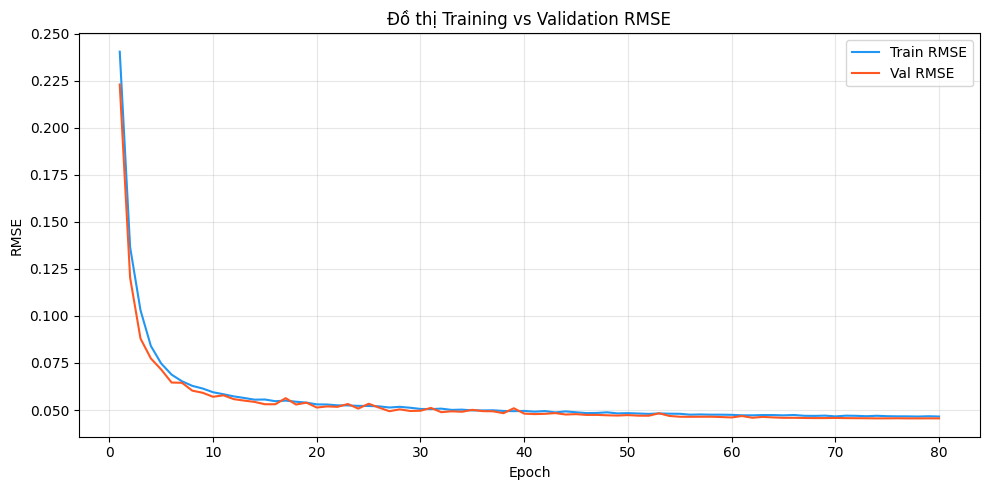

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
epochs_range = range(1, len(train_losses) + 1)

ax.plot(epochs_range, [l**0.5 for l in train_losses], label='Train RMSE', color='#2196F3')
ax.plot(epochs_range, [l**0.5 for l in val_losses],   label='Val RMSE',   color='#FF5722')
ax.set_xlabel('Epoch')
ax.set_ylabel('RMSE')
ax.set_title('Đồ thị Training vs Validation RMSE')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Đánh giá trên tập Validation

In [ ]:
# Nạp lại model tốt nhất
model.load_state_dict(torch.load('best_unet_noisyoffice.pth', map_location=DEVICE))
model.eval()

# Hiển thị kết quả trên tập Validation
n_show = 6
fig, axes = plt.subplots(n_show, 3, figsize=(12, 4 * n_show))
axes[0, 0].set_title('Ảnh Nhiễu (Input)', fontsize=14)
axes[0, 1].set_title('U-Net Output', fontsize=14)
axes[0, 2].set_title('Ground Truth', fontsize=14)

with torch.no_grad():
    for i in range(n_show):
        noisy, clean = val_ds_no_aug[i]
        pred = model(noisy.unsqueeze(0).to(DEVICE)).squeeze().cpu().numpy()

        axes[i, 0].imshow(noisy.squeeze(), cmap='gray')
        axes[i, 0].axis('off')
        axes[i, 1].imshow(pred, cmap='gray')
        axes[i, 1].axis('off')
        axes[i, 2].imshow(clean.squeeze(), cmap='gray')
        axes[i, 2].axis('off')

plt.suptitle('So sánh: Input → U-Net Output → Ground Truth', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## 14. Inference trên ảnh Real Noisy Office

> Ảnh Real Noisy là những ảnh thực tế (không phải mô phỏng), nằm trong thư mục `RealNoisyOffice/real_noisy_images_grayscale`.  
> Ảnh này **KHÔNG** có Ground Truth, nên ta chỉ xem trực quan kết quả khử nhiễu.

In [26]:
# --- Test lại sau khi đã train ---
# 1. Khởi tạo lại cấu trúc mô hình
model = UNet(in_ch=1, out_ch=1, base_ch=CFG.BASE_CH).to(DEVICE)

# 2. Đường dẫn tới file model đã lưu trên Drive của bạn
drive_model_path = '/content/drive/MyDrive/DAT301_SE190840_NguyenPhuongVu_Assigments/OCR_Testing/NoisyOffice_Models/best_unet_noisyoffice.pth'

# 3. Nạp trọng số đã train vào model
model.load_state_dict(torch.load(drive_model_path, map_location=DEVICE))
model.eval()

UNet(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (block): S

In [28]:
# --- CHAY INFERENCE TREN ANH REAL NOISY OFFICE ---
# 1. Khởi tạo lại cấu trúc mô hình
model = UNet(in_ch=1, out_ch=1, base_ch=CFG.BASE_CH).to(DEVICE)

# 2. Đường dẫn tới file model đã lưu trên Drive của bạn
drive_model_path = '/content/drive/MyDrive/DAT301_SE190840_NguyenPhuongVu_Assigments/OCR_Testing/NoisyOffice_Models/best_unet_noisyoffice.pth'

# 3. Nạp trọng số đã train vào model
model.load_state_dict(torch.load(drive_model_path, map_location=DEVICE))
model.eval()

# 4. Lấy danh sách ảnh Real Noisy
real_noisy_paths = sorted(glob.glob(os.path.join(CFG.REAL_NOISY_DIR, '*.png')))
print(f'So luong anh Real Noisy: {len(real_noisy_paths)}')

os.makedirs('UNet_Denoised_Results', exist_ok=True)

n_show = min(8, len(real_noisy_paths))
fig, axes = plt.subplots(n_show, 2, figsize=(14, 5 * n_show))

for i, path in enumerate(real_noisy_paths[:n_show]):
    # Doc anh goc (full resolution)
    img = np.array(Image.open(path).convert('L'))
    fname = os.path.basename(path)
    print(f'  [{i+1}/{n_show}] {fname} — kich thuoc: {img.shape[1]}x{img.shape[0]}', end=' ')

    # Du doan theo tung patch (giu nguyen do phan giai)
    denoised = patch_based_inference(model, img, patch_size=CFG.IMG_SIZE,
                                     overlap=64, device=DEVICE)
    print('-> Done!')

    # Luu ket qua
    pred_img = Image.fromarray(denoised)
    pred_img.save(f'UNet_Denoised_Results/denoised_{fname}')

    # Hien thi
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f'Real Noisy: {fname}', fontsize=10)
    axes[i, 0].axis('off')
    axes[i, 1].imshow(denoised, cmap='gray')
    axes[i, 1].set_title('U-Net Denoised (Patch-based, Full Res)', fontsize=10)
    axes[i, 1].axis('off')

plt.suptitle('Ket qua Khu nhieu tren anh Real Noisy Office (Full Resolution)', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

print(f'\nDa luu {n_show} anh denoised vao thu muc: UNet_Denoised_Results/')

Output hidden; open in https://colab.research.google.com to view.

## 15. Lưu model về Google Drive (tùy chọn)

In [ ]:
# Luu model da train vao Google Drive de su dung lai sau
import shutil

drive_save_dir = '/content/drive/MyDrive/DAT301_SE190840_NguyenPhuongVu_Assigments/OCR_Testing/NoisyOffice_Models'
os.makedirs(drive_save_dir, exist_ok=True)

shutil.copy('best_unet_noisyoffice.pth', os.path.join(drive_save_dir, 'best_unet_noisyoffice.pth'))
print(f'Model da duoc luu tai: {drive_save_dir}/best_unet_noisyoffice.pth')


Model da duoc luu tai: /content/drive/MyDrive/DAT301_SE190840_NguyenPhuongVu_Assigments/OCR_Testing/NoisyOffice_Models/best_unet_noisyoffice.pth


---

## Tổng kết

| Bước | Mô tả |
|------|--------|
| 1-3 | Thiết lập môi trường, tải dataset, cấu hình tham số |
| 4 | Ghép cặp `(Noisy → Clean)` bằng regex thay thế tên file |
| 5 | Xây dựng Dataset với Data Augmentation đồng bộ |
| 6 | Cấu trúc U-Net 4 tầng (y hệt bài Kaggle gốc) |
| 7-9 | Hàm tiện ích, DataLoader, xem thử mẫu |
| 10-12 | Huấn luyện 80 epochs + CosineAnnealing + lưu best model |
| 13 | Đánh giá trực quan trên tập Validation |
| 14 | Inference trên ảnh Real Noisy Office (ảnh thực tế) |
| 15 | Lưu model về Google Drive |